## Project summary

I tested whether cointegration-based pairs trading holds up out of sample.

1. **Initial test.** MCD/YUM passed the full-sample Engle-Granger test (p = 0.0129), but a single p-value cannot validate a pair, because of multiple testing and look-ahead bias.
2. **Formation/trading split.** Parameters were estimated on 2015-2019 and frozen. Out of sample (2020-2024) the spread stayed stationary (ADF p = 0.0244), but its mean shifted by about -6.92, roughly -1.4 formation-period standard deviations.
3. **Rolling diagnostic.** A two-year rolling regression showed beta drifting between about 0.2 and 0.65, so a static hedge ratio is unreliable.
4. **Batch screening.** Forty within-sector pairs were screened on the formation period at p < 0.05. Six passed, and all six failed out of sample (ADF p-values 0.31 to 0.87 on price levels, 0.20 to 0.88 on log prices).
5. **Walk-forward.** Each year from 2017 to 2024, pairs were re-screened on the previous two years (log prices, p < 0.05, 320 tests in total) and traded for the next year with rules fixed in advance: entry |z| > 2, exit |z| < 0.5, stop |z| > 4, equal weights, positions closed at year end, and no trading when no pair passed. Yearly gross returns were negative in five of the six traded years (only 2017 was positive, with two pairs, at +14.7%), and no trades were made in 2020 and 2023 because no pair passed the screen. The sum of yearly gross log returns was -0.29%, before transaction costs.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
ko = yf.download('KO', start='2015-01-01', end='2025-01-01')['Close']
pep = yf.download('PEP', start='2015-01-01', end='2025-01-01')['Close']
prices = pd.DataFrame({'KO': ko.squeeze(), 'PEP': pep.squeeze()})
prices = prices.dropna()
print(prices.shape)
print(prices.head())

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

(2516, 2)
                   KO        PEP
2015-01-02  29.215929  65.879173
2015-01-05  29.215929  65.383865
2015-01-06  29.437796  64.888603
2015-01-07  29.805220  66.785995
2015-01-08  30.165751  67.999779


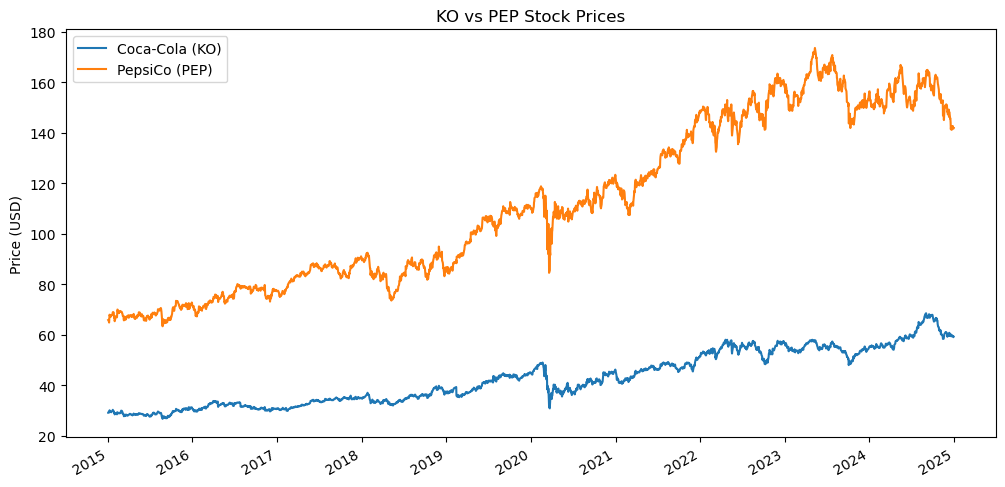

In [3]:
plt.figure(figsize=(12,6))
prices['KO'].plot(label='Coca-Cola (KO)')
prices['PEP'].plot(label='PepsiCo (PEP)')
plt.title('KO vs PEP Stock Prices')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [4]:
score, pvalue, _ = coint(prices['KO'], prices['PEP'])

print(f"Cointegration test p-value: {pvalue:.4f}")
if pvalue < 0.05:
    print("p-value < 0.05: KO and PEP are cointegrated - pairs trading is viable")
else:
    print("p-value >= 0.05: No significant cointegration found")

Cointegration test p-value: 0.2988
p-value >= 0.05: No significant cointegration found


In [5]:
mbg = yf.download('MBG.DE', start='2015-01-01', end='2025-01-01')['Close']
bmw = yf.download('BMW.DE', start='2015-01-01', end='2025-01-01')['Close']

prices3 = pd.DataFrame({'Mercedes': mbg.squeeze(), 'BMW': bmw.squeeze()})
prices3 = prices3.dropna()

score3, pvalue3, _ = coint(prices3['Mercedes'], prices3['BMW'])
print(f"Cointegration test p-value: {pvalue3:.4f}")
if pvalue3 < 0.05:
    print("p-value < 0.05: Mercedes and BMW are cointegrated - pairs trading is viable")
else:
    print("p-value >= 0.05: No significant cointegration found")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Cointegration test p-value: 0.0958
p-value >= 0.05: No significant cointegration found


In [6]:
mcd = yf.download('MCD', start='2015-01-01', end='2025-01-01')['Close']
yum = yf.download('YUM', start='2015-01-01', end='2025-01-01')['Close']

prices4 = pd.DataFrame({'MCD': mcd.squeeze(), 'YUM': yum.squeeze()})
prices4 = prices4.dropna()

score4, pvalue4, _ = coint(prices4['MCD'], prices4['YUM'])
print(f"Cointegration test p-value: {pvalue4:.4f}")
if pvalue4 < 0.05:
    print("p-value < 0.05: MCD and YUM are cointegrated - pairs trading is viable")
else:
    print("p-value >= 0.05: No significant cointegration found")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Cointegration test p-value: 0.0129
p-value < 0.05: MCD and YUM are cointegrated - pairs trading is viable


## However, a single p-value may not be enough

1. **Multiple testing.** If many pairs are tested at the 5% level, some will pass by chance. I tested 3 pairs and picked the one that passed.
2. **Look-ahead.** The full-sample test uses the same data to pick the pair, estimate the hedge ratio and run the test, so it cannot show the relationship will hold in the future. Here the p-value is 0.0129 on the full sample but 0.3241 on the formation period alone.

So I treat the p-value as an initial screen only, and check the pair out of sample: estimate the hedge ratio and spread statistics on 2015-2019, then test on 2020-2024.

formation cointegration p-value: 0.3241
beta_f: 0.49 mu_f: 0.0 sigma_f: 4.873


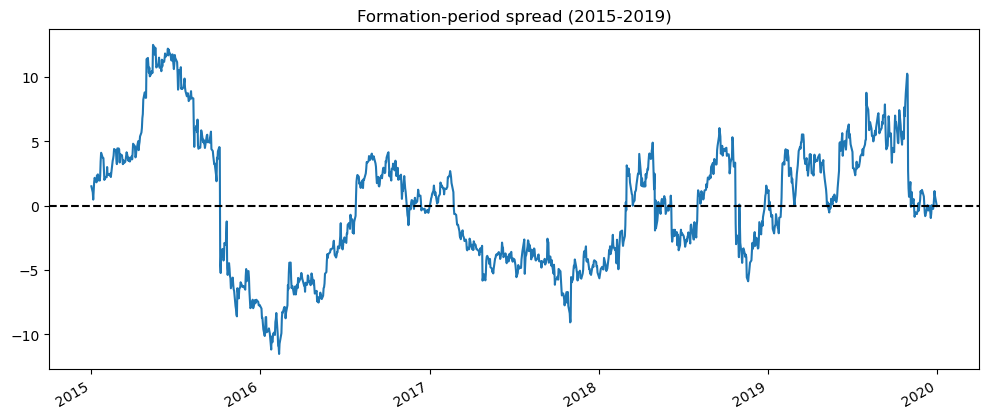

In [7]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller

split = '2020-01-01'
form = prices4.loc[:split]    # formation：2015-2019
trade = prices4.loc[split:]   # trading：2020-2024

_, p_form, _ = coint(form['YUM'], form['MCD'])
print('formation cointegration p-value:', round(p_form, 4))

X = sm.add_constant(form['MCD'])
m = sm.OLS(form['YUM'], X).fit()
alpha_f, beta_f = m.params['const'], m.params['MCD']

spread_form = form['YUM'] - beta_f * form['MCD'] - alpha_f
mu_f, sigma_f = spread_form.mean(), spread_form.std()
print('beta_f:', round(beta_f, 3), 'mu_f:', round(mu_f, 3), 'sigma_f:', round(sigma_f, 3))
spread_form.plot(figsize=(12,5), title='Formation-period spread (2015-2019)')
plt.axhline(0, color='black', ls='--')
plt.show()

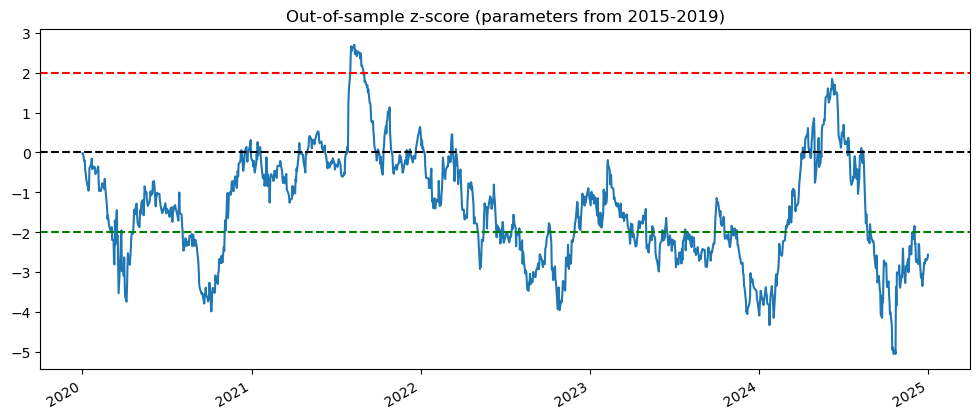

trading-period spread mean: -6.92
adfuller p-value: 0.0244


In [8]:
spread_trade = trade['YUM'] - beta_f * trade['MCD'] - alpha_f
z = (spread_trade - mu_f) / sigma_f

plt.figure(figsize=(12, 5))
z.plot(title='Out-of-sample z-score (parameters from 2015-2019)')
plt.axhline(0, color='black', ls='--')
plt.axhline(2, color='red', ls='--')
plt.axhline(-2, color='green', ls='--')
plt.show()

print('trading-period spread mean:', round(spread_trade.mean(), 3))
print('adfuller p-value:', round(adfuller(spread_trade)[1], 4))

Out of sample, the spread remains mean-reverting (ADF p = 0.0244), but its mean has shifted down by about 6.92 USD (roughly 1.4 formation-period standard deviations) relative to 2015-2019. The reversion is still present, but around a different level, so the parameters estimated on 2015-2019 no longer apply.

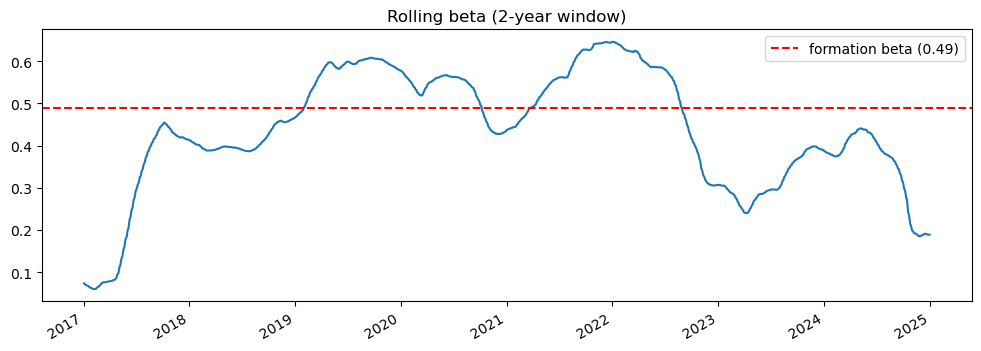

In [9]:
window = 504   # about 2 years

betas = []
for i in range(window, len(prices4)):
    chunk = prices4.iloc[i - window:i]
    X = sm.add_constant(chunk['MCD'])
    betas.append(sm.OLS(chunk['YUM'], X).fit().params['MCD'])

beta_roll = pd.Series(betas, index=prices4.index[window:])
beta_roll.plot(figsize=(12, 4), title='Rolling beta (2-year window)')
plt.axhline(beta_f, color='red', ls='--', label='formation beta (0.49)')
plt.legend()
plt.show()

I found the full-sample cointegration result was not robust: the hedge ratio drifted between roughly 0.2 and 0.65 over time, so a static beta estimated on 2015–2019 produced a persistently shifted spread out of sample. So MCD/YUM is not a clean pairs-trading candidate under a fixed hedge ratio. We need to choose another pair.

In [10]:
from itertools import combinations
import pandas as pd
import yfinance as yf
from statsmodels.tsa.stattools import coint

groups = {
    'consumer': ['KO', 'PEP', 'KDP', 'MNST', 'MDLZ'],
    'banks':    ['JPM', 'BAC', 'C', 'WFC', 'USB'],
    'energy':   ['XOM', 'CVX', 'COP', 'OXY', 'EOG'],
    'retail':   ['WMT', 'TGT', 'COST', 'HD', 'LOW'],
}

tickers = []
for sector, names_in_group in groups.items():
    for t in names_in_group:
        tickers.append(t)

raw = yf.download(tickers, start='2015-01-01', end='2025-01-01')['Close']
raw_form = raw.loc[:'2019-12-31']


px_form = raw_form.dropna()
print('px_form:', px_form.index.min().date(), px_form.index.max().date(), px_form.shape)

results = []
for sector, names_in_group in groups.items():
    for a, b in combinations(names_in_group, 2):
        _, p, _ = coint(px_form[a], px_form[b])
        results.append({'sector': sector, 'y': a, 'x': b, 'p': p})

res = pd.DataFrame(results).sort_values('p').reset_index(drop=True)
n_tests = len(res)
res['pass_raw'] = res['p'] < 0.05

print('pairs tested:', n_tests)
res.head(10)

[*********************100%***********************]  20 of 20 completed


px_form: 2015-01-02 2019-12-31 (1258, 20)
pairs tested: 40


,sector,y,x,p,pass_raw
0,retail,COST,LOW,0.010971,True
1,energy,XOM,EOG,0.020269,True
2,energy,XOM,OXY,0.027411,True
3,retail,WMT,LOW,0.033836,True
4,energy,XOM,CVX,0.041052,True
5,energy,XOM,COP,0.045263,True
6,retail,HD,LOW,0.077443,False
7,consumer,KO,PEP,0.088880,False
8,banks,WFC,USB,0.103891,False
9,consumer,MNST,MDLZ,0.110042,False


In [11]:
px_trade = raw.loc['2020-01-01':].dropna()
print('px_trade:', px_trade.index.min().date(), px_trade.index.max().date(), px_trade.shape)
picked = res[res['pass_raw']]
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

def oos_check(a, b, px_form, px_trade):
    X = sm.add_constant(px_form[b])
    m = sm.OLS(px_form[a], X).fit()
    alpha_f, beta_f = m.params['const'], m.params[b]
    s_form = px_form[a] - beta_f * px_form[b] - alpha_f
    mu_f, sigma_f = s_form.mean(), s_form.std()

    s_trade = px_trade[a] - beta_f * px_trade[b] - alpha_f
    z = (s_trade - mu_f) / sigma_f

    return {
        'pair': a + '/' + b,
        'beta_f': round(beta_f, 3),
        'trade_mean_in_sigma': round((s_trade.mean() - mu_f) / sigma_f, 2),
        'adf_p': round(adfuller(s_trade)[1], 4),
        'z_min': round(z.min(), 2),
        'z_max': round(z.max(), 2),
    }
oos = []
for _, row in picked.iterrows():
    oos.append(oos_check(row['y'], row['x'], px_form, px_trade))

oos_df = pd.DataFrame(oos)
oos_df

px_trade: 2020-01-02 2024-12-31 (1258, 20)


,pair,beta_f,trade_mean_in_sigma,adf_p,z_min,z_max
0,COST/LOW,2.994,0.28,0.8548,-10.63,20.89
1,XOM/EOG,0.174,6.20,0.8612,-9.10,20.91
2,XOM/OXY,0.224,7.97,0.8620,-7.73,23.77
3,WMT/LOW,0.346,-5.78,0.3143,-15.66,7.57
4,XOM/CVX,0.118,5.05,0.8655,-9.47,19.73
5,XOM/COP,0.085,5.17,0.8594,-9.31,18.79


Price-level hedge ratios were extreme (e.g. 2.99 for COST/LOW), so as a robustness check the same six pairs were re-tested with log prices. The conclusion did not change.

In [12]:
px_form_log  = np.log(raw_form.dropna())
px_trade_log = np.log(raw.loc['2020-01-01':].dropna())
oos = []
for _, row in picked.iterrows():
    oos.append(oos_check(row['y'], row['x'], px_form_log, px_trade_log))

oos_df_log = pd.DataFrame(oos)
oos_df_log

,pair,beta_f,trade_mean_in_sigma,adf_p,z_min,z_max
0,COST/LOW,1.279,-1.17,0.2005,-6.00,11.01
1,XOM/EOG,0.227,3.67,0.8696,-12.93,13.43
2,XOM/OXY,0.205,5.49,0.8756,-9.16,15.24
3,WMT/LOW,1.026,-2.40,0.2140,-6.26,6.62
4,XOM/CVX,0.171,2.71,0.8673,-14.01,12.89
5,XOM/COP,0.060,3.02,0.8592,-13.50,12.40


Parameters (alpha, beta, mu, sigma) were estimated on the formation period (2015-2019) and frozen. Applied to the trading period (2020-2024) with log prices, all six candidate pairs failed the ADF test (p-values 0.20 to 0.88, all above 0.05), so the spread was not stationary out of sample for any of them. Since frozen parameters did not carry over, the next step is a walk-forward design in which parameters are re-estimated periodically.

In [13]:
import numpy as np
import pandas as pd
from itertools import combinations
from statsmodels.tsa.stattools import coint

screen_rows = []      
picked_by_year = {}   

for year in range(2017, 2025):                   
    est_start = f'{year-2}-01-01'
    est_end   = f'{year-1}-12-31'
    px_est = np.log(raw.loc[est_start:est_end].dropna())

    picked_year = []
    for sector, names in groups.items():
        for a, b in combinations(names, 2):
            _, p, _ = coint(px_est[a], px_est[b])
            screen_rows.append({'year': year, 'sector': sector, 'y': a, 'x': b, 'p': p})
            if p < 0.05:
                picked_year.append((a, b))

    picked_by_year[year] = picked_year
    print(year, 'est window:', px_est.index.min().date(), '-', px_est.index.max().date(),
          '| rows:', len(px_est), '| picked:', len(picked_year))

screen_df = pd.DataFrame(screen_rows)
print('total tests:', len(screen_df))

2017 est window: 2015-01-02 - 2016-12-30 | rows: 504 | picked: 2
2018 est window: 2016-01-04 - 2017-12-29 | rows: 503 | picked: 8
2019 est window: 2017-01-03 - 2018-12-31 | rows: 502 | picked: 3
2020 est window: 2018-01-02 - 2019-12-31 | rows: 503 | picked: 0
2021 est window: 2019-01-02 - 2020-12-31 | rows: 505 | picked: 6
2022 est window: 2020-01-02 - 2021-12-31 | rows: 505 | picked: 3
2023 est window: 2021-01-04 - 2022-12-30 | rows: 503 | picked: 0
2024 est window: 2022-01-03 - 2023-12-29 | rows: 501 | picked: 1
total tests: 320


## Walk-forward backtest

Since frozen parameters did not carry over, parameters are now re-estimated every year. All rules below were fixed before running the backtest and were not tuned afterwards.

**Timeline.** For each trading year from 2017 to 2024, pairs are screened and parameters are estimated on the previous two calendar years only, then traded for the following year. The trading year never enters its own estimation window.

**Screening.** Log prices, Engle-Granger test on all 40 within-sector pairs, selected if p < 0.05. Over eight years this is 320 tests, with no multiple-testing correction.

**Parameters.** For each selected pair, alpha and beta are estimated by OLS on the estimation window, and the spread mean (mu) and standard deviation (sigma) are computed from that window. All four are then frozen for the trading year.

**Trading rules.**
- Signal: z = (spread - mu) / sigma, using the frozen parameters.
- Entry: short the spread if z > 2 (sell A, buy beta units of B); long the spread if z < -2.
- Exit: close the position when |z| < 0.5.
- Stop-loss: close when |z| > 4 and do not trade that pair again in the same year.
- Positions are decided at the close and earn the next day's spread change (`pos.shift(1)`), so there is no look-ahead.
- The year's PnL is the sum of daily spread changes (log units).

**Portfolio.** Selected pairs are equally weighted within each year. If no pair passes the screen, the portfolio stays in cash and the return for that year is 0.

**Not included.** Transaction costs and borrow fees, so all results are gross.

In [14]:
def make_position(z):
    pos = 0
    stopped = False
    positions = []

    for zt in z:
        if pos == 0:
            if not stopped:
                if zt > 2:
                    pos = -1
                elif zt < -2:
                    pos = 1
        else:
            if abs(zt) > 4:
                pos = 0
                stopped = True
            elif abs(zt) < 0.5:
                pos = 0
        positions.append(pos)

    return pd.Series(positions, index=z.index)
import statsmodels.api as sm

def get_z(a, b, year, raw):
    est = np.log(raw.loc[f'{year-2}-01-01':f'{year-1}-12-31'].dropna())
    trd = np.log(raw.loc[f'{year}-01-01':f'{year}-12-31'].dropna())

    X = sm.add_constant(est[b])
    m = sm.OLS(est[a], X).fit()
    alpha, beta = m.params['const'], m.params[b]
    s_est = est[a] - beta * est[b] - alpha
    mu, sigma = s_est.mean(), s_est.std()

    spread = trd[a] - beta * trd[b] - alpha
    z = (spread - mu) / sigma
    return z, spread, beta

a, b = picked_by_year[2018][0]
z, spread, beta = get_z(a, b, 2018, raw)
print(a, b, round(beta, 3), len(z))
z.describe()

JPM BAC 0.735 251


count    251.000000
mean       2.279014
std        0.880713
min        0.777516
25%        1.528513
50%        2.073487
75%        2.839582
max        4.330670
dtype: float64

In [15]:
pos = make_position(z)
daily = pos.shift(1) * spread.diff()
print(round(daily.sum(), 4), (pos != 0).sum())

-0.0492 186


In [16]:
year = 2018
for a, b in picked_by_year[year]:
    z, spread, beta = get_z(a, b, year, raw)
    pos = make_position(z)
    daily = pos.shift(1) * spread.diff()
    print(a, b, round(daily.sum(), 4))

JPM BAC -0.0492
JPM C -0.0807
BAC USB -0.089
XOM OXY -0.0491
CVX COP -0.0882
COP EOG -0.1251
WMT HD 0.2631
COST HD -0.0634


In [17]:
year_ret = {}

for year in range(2017, 2025):
    rets = []
    for a, b in picked_by_year[year]:
        z, spread, beta = get_z(a, b, year, raw)
        pos = make_position(z)
        daily = pos.shift(1) * spread.diff()
        rets.append(daily.sum())

    if len(rets) == 0:
        year_ret[year] = 0
    else:
        year_ret[year] = sum(rets) / len(rets)

    print(year, len(rets), round(year_ret[year], 4))

2017 2 0.1465
2018 8 -0.0352
2019 3 -0.0003
2020 0 0
2021 6 -0.0363
2022 3 -0.067
2023 0 0
2024 1 -0.0105


In [18]:
yr = pd.Series(year_ret)
print(round(yr.sum(), 4), (yr > 0).sum(), 'of', len(yr))

-0.0029 1 of 8


## Conclusion

In this candidate pool, cointegration-based pairs trading showed no robust edge. A full-sample p-value did not survive a formation/trading split, and a walk-forward backtest with annual re-estimation was unprofitable once costs are considered. This does not show that pairs trading cannot work; it shows that in-sample significance alone is not evidence of a tradable pair.


## Limitations

- Small hand-picked pool (20 stocks, 4 sectors).
- Two-year estimation window, so the cointegration test has low power.
- No multiple-testing correction was applied to the screening threshold. With 40 tests at p < 0.05, about 2 pairs are expected to pass by chance, and with 320 tests in the walk-forward, about 16. This is consistent with most selected pairs failing out of sample.
- Results are gross of transaction costs and borrow fees, so they are an upper bound on achievable returns.
- Pair order (which stock is regressed on which) was fixed by list order, and the Engle-Granger test is not symmetric.
- Daily returns are summed in log units and averaged across pairs, which approximates, but is not exactly, a capital-weighted return.
- All walk-forward rules were fixed before the backtest and not tuned afterwards.